# Parametric amplification and optical parametric oscillators

Notebook 145 (second harmonic generation and phase matching) combined two
photons into one. The same $\chi^{(2)}$ also works the other way: a
pump photon $\omega_p$ splits into a **signal** $\omega_s$ and an
**idler** $\omega_i$ with $\omega_s + \omega_i = \omega_p$. A weak signal
is amplified, and an idler is made from nothing at the difference
frequency. In a resonator the parametric gain makes an **optical
parametric oscillator** (OPO): a source whose wavelength is set by phase
matching, tunable over octaves from the visible to the mid-infrared,
where few lasers exist.

This notebook uses the three wave equations of the `nonlinear` module for
MgO-doped periodically poled lithium niobate (PPLN) pumped at 1064 nm,
the workhorse of mid-infrared OPOs:

1. sum and difference frequency generation: photons are counted,
2. parametric amplification: exponential gain and its bandwidth,
3. saturation and back conversion,
4. tuning: poling period, temperature, and the angle of a BBO OPO,
5. the OPO: threshold of singly and doubly resonant oscillators, build-up
   and the pump depletion of the singly resonant OPO.

The pulsed side of the same physics, in fibres, is in notebook 121 (SPM and solitons in fibres); the Kerr effect in notebook 147 (Kerr effect and self-focusing).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import nonlinear as NL

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
T_OVEN = 100.0                                     # °C, a usual PPLN oven temperature
d_qpm = NL.qpm_d_eff(NL.CRYSTALS["MgO:LN"]["d"]["d33"])*1E-12


def ppln(wavelengths_nm):
    """extraordinary indices of MgO:LN at the oven temperature"""
    return [float(NL.mgo_ln_ne(w, T_OVEN)) for w in wavelengths_nm]

## 1. Sum and difference frequency generation

Three waves $\omega_1 + \omega_2 = \omega_3$ obey, with the amplitudes
normalized to intensities ($|a_j|^2 = I_j$),

$$\frac{da_1}{dz} = i\omega_1K\,a_3a_2^*e^{-i\Delta kz},\quad
\frac{da_2}{dz} = i\omega_2K\,a_3a_1^*e^{-i\Delta kz},\quad
\frac{da_3}{dz} = i\omega_3K\,a_1a_2e^{i\Delta kz},$$

$K = d_{\rm eff}\sqrt{2/(n_1n_2n_3\varepsilon_0c^3)}$, $\Delta k = k_1 +
k_2 - k_3$ (`NL.three_wave()`). The factors $\omega_j$ make the equations
count photons: each photon at $\omega_3$ is made from one at $\omega_1$
and one at $\omega_2$ (**Manley–Rowe relations**), so that the fluxes
$I_j/\omega_j$ change in step. In **sum frequency generation** (SFG) the
weaker of the two input photon fluxes can be converted completely. In
**difference frequency generation** (DFG) a strong pump $\omega_3$ and a
weak signal $\omega_1$ make the idler $\omega_2 = \omega_3 - \omega_1$, and
every idler photon comes with a new signal photon: the signal is amplified.

The example is first order quasi-phase matched MgO:PPLN at 100 °C for
1064 nm = 1550 nm + 3393 nm, with $d_{\rm eff} = 2d_{33}/\pi$ = 16 pm/V.

idler 3393 nm, QPM period 30.31 µm at 100 °C
SFG: largest conversion of the weaker idler photons 1.0000 at z = 25.2 mm


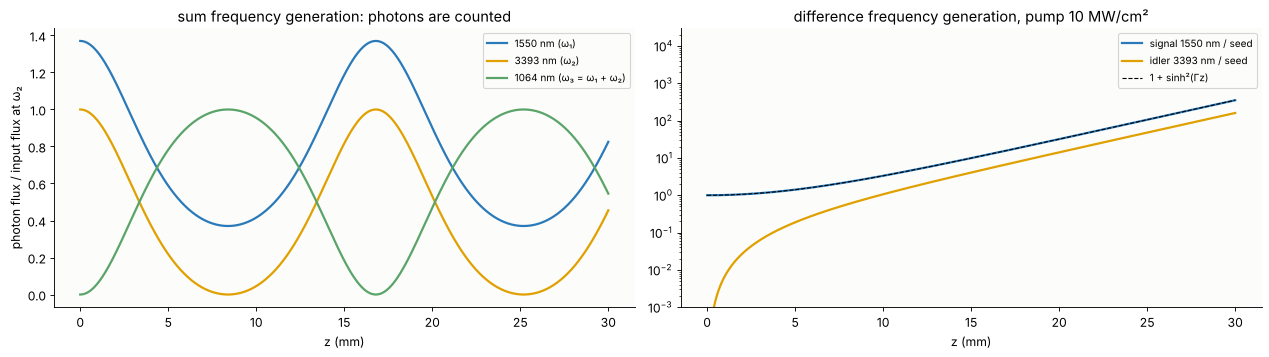

DFG: Gamma = 120.9 1/m, signal gain after 30 mm 352.41, idler / seed 160.51


In [2]:
wl_p, wl_s = 1064.0, 1550.0
wl_i = 1/(1/wl_p - 1/wl_s)
wls_m = np.array([wl_s, wl_i, wl_p])*1E-9
om = 2*np.pi*NL.C0/wls_m
n_sip = ppln([wl_s, wl_i, wl_p])
period = NL.qpm_period("MgO:LN", wl_s, wl_i, T=T_OVEN)
print("idler {:.0f} nm, QPM period {:.2f} µm at {:.0f} °C".format(wl_i, period*1E6, T_OVEN))
z = np.linspace(0, 30E-3, 600)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
# sum frequency: strong 1550 nm and 3393 nm make 1064 nm
I_s, I_i = 30E10, 10E10                       # 30 and 10 MW/cm² (W/m²)
a = NL.three_wave(z, [np.sqrt(I_s), np.sqrt(I_i), 0], wls_m, n_sip, d_qpm)
flux0 = I_i/om[1]
ax = axes[0]
for j, c, lab in ((0, BLUE, "1550 nm (ω₁)"), (1, ORANGE, "3393 nm (ω₂)"), (2, GREEN, "1064 nm (ω₃ = ω₁ + ω₂)")):
    ax.plot(z*1E3, np.abs(a[:, j])**2/om[j]/flux0, color=c, lw=2, label=lab)
ax.set_xlabel("z (mm)"); ax.set_ylabel("photon flux / input flux at ω₂")
ax.set_title("sum frequency generation: photons are counted"); ax.legend(fontsize=9)
print("SFG: largest conversion of the weaker idler photons {:.4f} at z = {:.1f} mm".format(
    np.max(np.abs(a[:, 2])**2/om[2]/flux0), z[np.argmax(np.abs(a[:, 2]))]*1E3))
# difference frequency: strong pump at 1064 nm and a weak 1550 nm seed make 3393 nm
I_p, I_seed = 10E10, 1E6
a = NL.three_wave(z, [np.sqrt(I_seed), 0, np.sqrt(I_p)], wls_m, n_sip, d_qpm)
ax = axes[1]
ax.semilogy(z*1E3, np.abs(a[:, 0])**2/I_seed, color=BLUE, lw=2, label="signal 1550 nm / seed")
ax.semilogy(z*1E3, np.maximum(np.abs(a[:, 1])**2, 1E-30)/I_seed, color=ORANGE, lw=2, label="idler 3393 nm / seed")
Gam = NL.parametric_gain_coefficient(I_p, d_qpm, wls_m, n_sip)
ax.semilogy(z*1E3, NL.opa_gain(Gam, z), color="k", lw=1, ls="--", label="1 + sinh²(Γz)")
ax.set_ylim(1E-3, None)
ax.set_xlabel("z (mm)"); ax.set_title("difference frequency generation, pump 10 MW/cm²")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print("DFG: Gamma = {:.1f} 1/m, signal gain after 30 mm {:.2f}, idler / seed {:.2f}".format(
    Gam, np.abs(a[-1, 0])**2/I_seed, np.abs(a[-1, 1])**2/I_seed))

SFG of 30 MW/cm² at 1550 nm and 10 MW/cm² at 3393 nm converts all
3393 nm photons after 25 mm, then the process reverses. In DFG the 10 MW/cm²
pump amplifies the 1550 nm seed 350 times in 30 mm, and the idler, which
started at zero, reaches 160 times the seed: the difference of one
photon per photon, times the ratio of photon energies. Signal and idler
then grow together at the rate of the parametric gain coefficient.

## 2. Parametric amplification

With the pump undepleted, signal and idler grow as $\cosh$ and $\sinh$ of
$gz$; the power gain of the signal is

$$G = 1 + \frac{\Gamma^2}{g^2}\sinh^2(gL),\qquad
g = \sqrt{\Gamma^2 - (\Delta k/2)^2},\qquad
\Gamma^2 = \frac{8\pi^2d_{\rm eff}^2I_p}{n_sn_in_p\varepsilon_0c\lambda_s\lambda_i}$$

(`NL.opa_gain()`, `NL.parametric_gain_coefficient()`). For small $\Gamma L$
the gain is $1 + \Gamma^2L^2$, quadratic like SHG; for large $\Gamma L$ it
grows as $e^{2\Gamma L}/4$. The phase mismatch at other signal wavelengths
(the idler follows from energy conservation) limits the **gain
bandwidth**. Near degeneracy ($\omega_s = \omega_i = \omega_p/2$) signal and
idler are the same wave, the mismatch changes only in second order, and
the bandwidth becomes very large: the basis of optical parametric chirped
pulse amplification (OPCPA).

  10 MW/cm²: peak gain       349, gain bandwidth (FWHM of the gain)   2.2 nm
  30 MW/cm²: peak gain  7.07e+04, gain bandwidth (FWHM of the gain)   3.7 nm
 100 MW/cm²: peak gain  2.27e+09, gain bandwidth (FWHM of the gain)   4.4 nm
degenerate at 2128 nm: gain bandwidth   230 nm


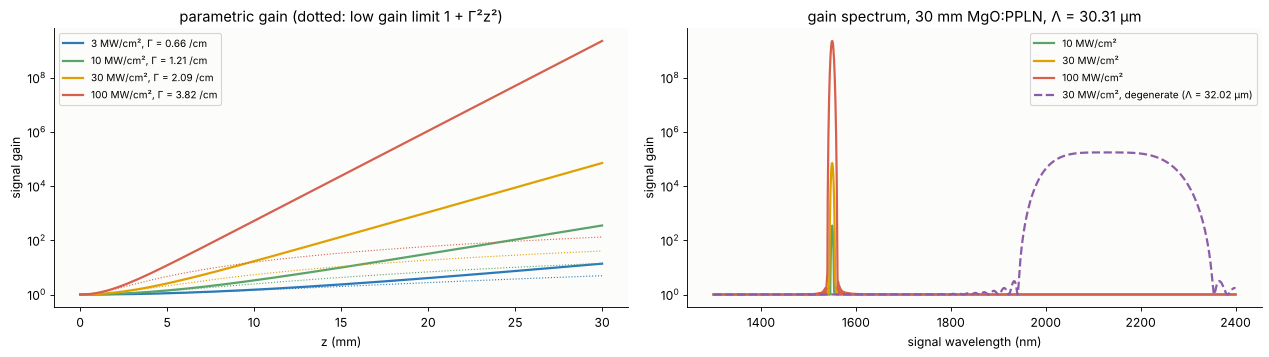

In [3]:
L_opa = 30E-3
I_ps = np.array([3, 10, 30, 100])*1E10           # MW/cm² to W/m²
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
ax = axes[0]
zz = np.linspace(0, L_opa, 300)
for Ip, c in zip(I_ps, (BLUE, GREEN, ORANGE, RED)):
    G = NL.parametric_gain_coefficient(Ip, d_qpm, wls_m, n_sip)
    ax.semilogy(zz*1E3, NL.opa_gain(G, zz), color=c, lw=2, label=f"{Ip/1E10:g} MW/cm², Γ = {G/100:.2f} /cm")
    ax.semilogy(zz*1E3, 1 + (G*zz)**2, color=c, lw=1, ls=":")
ax.set_xlabel("z (mm)"); ax.set_ylabel("signal gain"); ax.legend(fontsize=9)
ax.set_title("parametric gain (dotted: low gain limit 1 + Γ²z²)")
ax = axes[1]
ws = np.linspace(1300, 2400, 1500)
for Ip, c in zip(I_ps[1:], (GREEN, ORANGE, RED)):
    wi = 1/(1/wl_p - 1/ws)
    dk = NL.delta_k("MgO:LN", ws, wi, T=T_OVEN, period=period)
    n_l = [NL.mgo_ln_ne(ws, T_OVEN), NL.mgo_ln_ne(wi, T_OVEN), NL.mgo_ln_ne(wl_p, T_OVEN)]
    G = NL.parametric_gain_coefficient(Ip, d_qpm, [ws*1E-9, wi*1E-9, wl_p*1E-9], n_l)
    g = NL.opa_gain(G, L_opa, dk)
    ax.semilogy(ws, g, color=c, lw=2, label=f"{Ip/1E10:g} MW/cm²")
    print("{:4.0f} MW/cm²: peak gain {:9.3g}, gain bandwidth (FWHM of the gain) {:5.1f} nm".format(
        Ip/1E10, g.max(), np.ptp(ws[g > (g.max() + 1)/2])))
period_deg = NL.qpm_period("MgO:LN", 2*wl_p, T=T_OVEN)
wi = 1/(1/wl_p - 1/ws)
dk = NL.delta_k("MgO:LN", ws, wi, T=T_OVEN, period=period_deg)
n_l = [NL.mgo_ln_ne(ws, T_OVEN), NL.mgo_ln_ne(wi, T_OVEN), NL.mgo_ln_ne(wl_p, T_OVEN)]
G = NL.parametric_gain_coefficient(30E10, d_qpm, [ws*1E-9, wi*1E-9, wl_p*1E-9], n_l)
g = NL.opa_gain(G, L_opa, dk)
ax.semilogy(ws, g, color=PURPLE, lw=2, ls="--", label=f"30 MW/cm², degenerate (Λ = {period_deg*1E6:.2f} µm)")
print("degenerate at 2128 nm: gain bandwidth {:5.0f} nm".format(np.ptp(ws[g > (g.max() + 1)/2])))
ax.set_xlabel("signal wavelength (nm)"); ax.set_ylabel("signal gain")
ax.set_title(f"gain spectrum, 30 mm MgO:PPLN, Λ = {period*1E6:.2f} µm"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In 30 mm of PPLN, 10 MW/cm² gives a gain of 350, 100 MW/cm² a gain of 2 × 10⁹:
a single photon becomes a measurable pulse. Such gains are reached with
pulsed pumps; a continuous pump of a few watts focused into PPLN gives
percent level gains, which is why continuous parametric sources need a
resonator. The gain bandwidth is a few nm at 1550 nm and grows only
slowly with the gain, while the degenerate amplifier at 2128 nm amplifies
230 nm at once.

## 3. Saturation and back conversion

At high gain the signal grows until it has taken the pump: then the
process reverses, signal and idler photons recombine into pump photons,
and the energy oscillates between the waves. Where the pump is gone
depends on the seed: a weaker seed needs more length.

seed   1e+00 W/m²: pump fully depleted at  68.7 mm
seed   1e+03 W/m²: pump fully depleted at  52.2 mm
seed   1e+06 W/m²: pump fully depleted at  35.7 mm


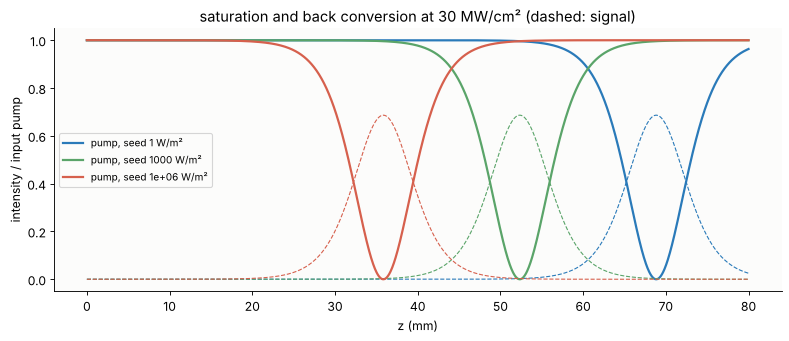

photon limit of the signal: omega_s/omega_p = 0.686


In [4]:
Ip = 30E10
zl = np.linspace(0, 80E-3, 1600)
fig, ax = plt.subplots(figsize=(10, 4.4))
for seed, c in ((1E0, BLUE), (1E3, GREEN), (1E6, RED)):
    a = NL.three_wave(zl, [np.sqrt(seed), 0, np.sqrt(Ip)], wls_m, n_sip, d_qpm)
    ax.plot(zl*1E3, np.abs(a[:, 2])**2/Ip, color=c, lw=2, label=f"pump, seed {seed:g} W/m²")
    ax.plot(zl*1E3, np.abs(a[:, 0])**2/Ip, color=c, lw=1, ls="--")
    k = np.nonzero(np.abs(a[:, 2])**2 < 1E-3*Ip)[0][0]
    print("seed {:7.0e} W/m²: pump fully depleted at {:5.1f} mm".format(seed, zl[k]*1E3))
ax.set_xlabel("z (mm)"); ax.set_ylabel("intensity / input pump")
ax.set_title("saturation and back conversion at 30 MW/cm² (dashed: signal)"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print("photon limit of the signal: omega_s/omega_p = {:.3f}".format(om[0]/om[2]))

The signal can take at most $\omega_s/\omega_p$ = 69 % of the pump power at
1550 nm; the rest goes into the idler. Complete depletion happens after
36 to 69 mm for seeds from 10⁶ down to 1 W/m², then back conversion
sets in: real amplifiers are designed to stop at the first depletion
point, and with Gaussian beams and pulses the depletion is uneven across
the beam, which limits the efficiency to about half the pump.

## 4. Tuning

The signal and idler wavelengths are those for which $\Delta k = 0$ with
the poling period: `NL.qpm_signal()` solves for the signal wavelength at
given period and temperature. A crystal with several gratings side by
side (a multi-grating PPLN) is tuned in steps by translating it and
continuously by the temperature. Birefringent crystals are tuned by the
angle: a BBO crystal pumped at 355 nm (the third harmonic of Nd:YAG) is
the classic visible OPO.

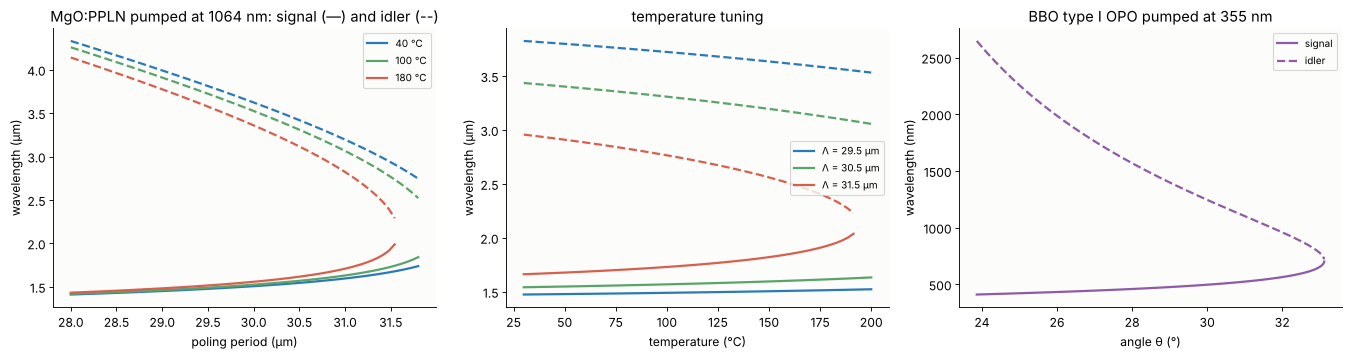

BBO at 355 nm: 23.9° to 33.1° tunes the signal from 410 to 700 nm (degenerate 33.1°)


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
periods = np.linspace(28.0, 31.8, 60)*1E-6
for T, c in ((40.0, BLUE), (100.0, GREEN), (180.0, RED)):
    sig = np.array([NL.qpm_signal("MgO:LN", wl_p, P, T=T) for P in periods])
    idl = 1/(1/wl_p - 1/sig)
    ax.plot(periods*1E6, sig/1E3, color=c, lw=2, label=f"{T:.0f} °C")
    ax.plot(periods*1E6, idl/1E3, color=c, lw=2, ls="--")
ax.set_xlabel("poling period (µm)"); ax.set_ylabel("wavelength (µm)")
ax.set_title("MgO:PPLN pumped at 1064 nm: signal (—) and idler (--)"); ax.legend(fontsize=9)
ax = axes[1]
Ts = np.linspace(30, 200, 60)
for P, c in ((29.5E-6, BLUE), (30.5E-6, GREEN), (31.5E-6, RED)):
    sig = np.array([NL.qpm_signal("MgO:LN", wl_p, P, T=T) for T in Ts])
    ax.plot(Ts, sig/1E3, color=c, lw=2, label=f"Λ = {P*1E6:.1f} µm")
    ax.plot(Ts, 1/(1/wl_p - 1/sig)/1E3, color=c, lw=2, ls="--")
ax.set_xlabel("temperature (°C)"); ax.set_ylabel("wavelength (µm)"); ax.legend(fontsize=9)
ax.set_title("temperature tuning")
ax = axes[2]
wl_p3 = 355.0
ws3 = np.linspace(410, 700, 120)
th3 = np.array([NL.phase_matching_angle("BBO", w, 1/(1/wl_p3 - 1/w), pol="ooe") for w in ws3])
ax.plot(np.degrees(th3), ws3, color=PURPLE, lw=2, label="signal")
ax.plot(np.degrees(th3), 1/(1/wl_p3 - 1/ws3), color=PURPLE, lw=2, ls="--", label="idler")
ax.set_xlabel("angle θ (°)"); ax.set_ylabel("wavelength (nm)")
ax.set_title("BBO type I OPO pumped at 355 nm"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print("BBO at 355 nm: {:.1f}° to {:.1f}° tunes the signal from 410 to 700 nm (degenerate {:.1f}°)".format(
    np.degrees(np.nanmin(th3)), np.degrees(np.nanmax(th3)), np.degrees(NL.phase_matching_angle("BBO", 710.0, pol="ooe"))))

Between periods of 28 and 31.8 µm, a 1064 nm pumped PPLN OPO covers signals
from 1.4 to 2 µm and idlers from 4.4 µm down to degeneracy at 2.13 µm;
heating from 30 to 200 °C shifts the signal by 50 nm far from degeneracy
and by 400 nm close to it, where the tuning curves turn over. The idler beyond
4 to 5 µm is absorbed by the crystal itself. BBO pumped at 355 nm tunes the
signal from 410 to 700 nm between 23.9° and 33.1°.

## 5. The optical parametric oscillator

An OPO resonates the signal (singly resonant, SRO), or signal and idler
(doubly resonant, DRO). It starts when the parametric gain per pass
exceeds the losses: with the round trip amplitude feedback $r_s$, $r_i$
(the square roots of the power fractions kept) the plane wave threshold is

$$\cosh\Gamma L = \frac{1 + r_sr_i}{r_s + r_i},$$

for small losses $\Gamma^2L^2 = 2(1 - r_s)$ (SRO) and
$\Gamma^2L^2 = (1 - r_s)(1 - r_i)$ (DRO) (`NL.opo_threshold()`). The DRO
threshold is lower by the product of the small losses, but it needs two
resonances at once, which makes its output jump between modes; the SRO
is the stable continuous source.

In [6]:
L_opo = 50E-3
w_beam = 50E-6
area = np.pi*w_beam**2/2                         # P = I_peak * area for a Gaussian beam
print("50 mm MgO:PPLN, pump at 1064 nm, signal 1550 nm; plane wave thresholds:")
for name, rs, ri in (("SRO, 2 % signal loss", 0.98, 0.0), ("SRO, 10 % signal loss", 0.90, 0.0),
                     ("DRO, 2 % on each", 0.98, 0.98), ("DRO, 0.5 % on each", 0.995, 0.995)):
    I_th = NL.opo_threshold(L_opo, d_qpm, wls_m, n_sip, np.sqrt(rs), np.sqrt(ri))
    print("  {:24s} {:8.3g} kW/cm², {:7.3g} W for a {:.0f} µm beam".format(name, I_th/1E7, I_th*area,
                                                                       w_beam*1E6))

50 mm MgO:PPLN, pump at 1064 nm, signal 1550 nm; plane wave thresholds:
  SRO, 2 % signal loss         5.55 kW/cm²,   0.218 W for a 50 µm beam
  SRO, 10 % signal loss        29.4 kW/cm²,    1.15 W for a 50 µm beam
  DRO, 2 % on each           0.0279 kW/cm²,  0.0011 W for a 50 µm beam
  DRO, 0.5 % on each        0.00172 kW/cm², 6.75e-05 W for a 50 µm beam


N = 1.50: output within 10 % of its final value after 2489 round trips


N = 2.47: output within 10 % of its final value after 1164 round trips


N = 4.00: output within 10 % of its final value after 582 round trips


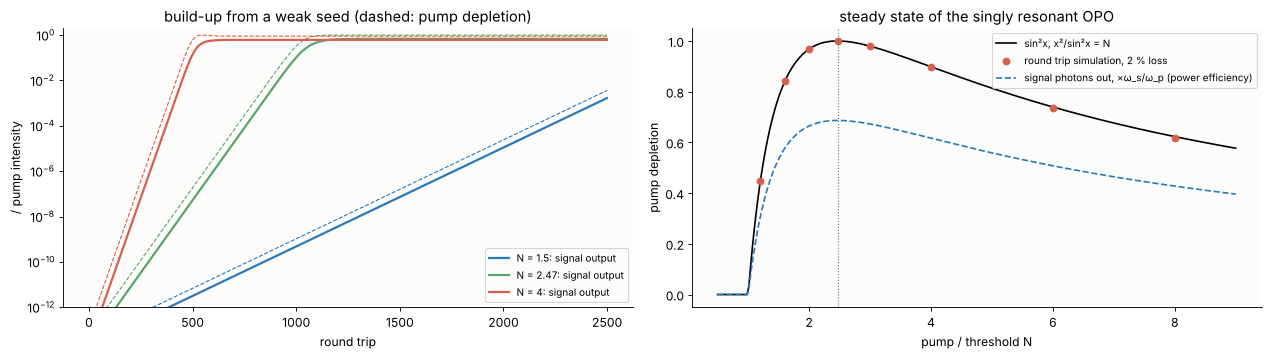

N = 1.20: depletion 0.449 (formula 0.448)
N = 1.60: depletion 0.841 (formula 0.840)
N = 2.00: depletion 0.969 (formula 0.968)
N = 2.47: depletion 1.000 (formula 1.000)
N = 3.00: depletion 0.979 (formula 0.980)
N = 4.00: depletion 0.896 (formula 0.898)
N = 6.00: depletion 0.735 (formula 0.740)
N = 8.00: depletion 0.618 (formula 0.623)


In [7]:
r_s = np.sqrt(0.98)                              # 2 % output coupling of the signal per round trip
I_th = NL.opo_threshold(L_opo, d_qpm, wls_m, n_sip, r_s)
z2 = np.array([0.0, L_opo])
rng = np.random.default_rng(3)


def run_sro(N, round_trips, seed=1E-6):
    Ip = N*I_th
    a_s = seed*np.sqrt(Ip) + 0j
    sig, pump = [], []
    for _ in range(round_trips):
        a = NL.three_wave(z2, [a_s, 0, np.sqrt(Ip)], wls_m, n_sip, d_qpm, rtol=1E-7, atol=1E-9)
        sig.append(np.abs(a[-1, 0])**2/Ip)
        pump.append(np.abs(a[-1, 2])**2/Ip)
        a_s = a[-1, 0]*r_s
    return np.array(sig), np.array(pump)


fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
ax = axes[0]
for N, c in ((1.5, BLUE), (2.47, GREEN), (4.0, RED)):
    sig, pump = run_sro(N, 2500)
    ax.semilogy(sig*(1 - r_s**2), color=c, lw=2, label=f"N = {N:g}: signal output")
    ax.semilogy(1 - pump, color=c, lw=1, ls="--")
    print("N = {:4.2f}: output within 10 % of its final value after {} round trips".format(
        N, np.nonzero(sig > 0.9*sig[-1])[0][0]))
ax.set_ylim(1E-12, 2)
ax.set_xlabel("round trip"); ax.set_ylabel("/ pump intensity")
ax.set_title("build-up from a weak seed (dashed: pump depletion)"); ax.legend(fontsize=9)
ax = axes[1]
Ns = np.linspace(0.5, 9, 300)
ax.plot(Ns, NL.sro_pump_depletion(Ns), color="k", lw=1.5, label="sin²x, x²/sin²x = N")
Nsim = (1.2, 1.6, 2.0, 2.47, 3.0, 4.0, 6.0, 8.0)
dep = []
for N in Nsim:
    Ip = N*I_th
    a_s = 0.3*np.sqrt(Ip) + 0j                     # start near the steady state
    for _ in range(4000 if N < 1.5 else 1500):
        a = NL.three_wave(z2, [a_s, 0, np.sqrt(Ip)], wls_m, n_sip, d_qpm, rtol=1E-7, atol=1E-9)
        a_s = a[-1, 0]*r_s
    dep.append(1 - np.abs(a[-1, 2])**2/Ip)
ax.plot(Nsim, dep, "o", color=RED, label="round trip simulation, 2 % loss")
ax.plot(Ns, NL.sro_pump_depletion(Ns)*om[0]/om[2], color=BLUE, lw=1.5, ls="--",
        label="signal photons out, ×ω_s/ω_p (power efficiency)")
ax.axvline(np.pi**2/4, color=GREY, ls=":", lw=1)
ax.set_xlabel("pump / threshold N"); ax.set_ylabel("pump depletion")
ax.set_title("steady state of the singly resonant OPO"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
for N, d in zip(Nsim, dep):
    print("N = {:4.2f}: depletion {:.3f} (formula {:.3f})".format(N, d, NL.sro_pump_depletion(N)))

In [8]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 29 s


From a seed of 10⁻¹² the output settles after 580 round trips at four
times threshold, 1160 at 2.47 times, and needs more than 2500 at 1.5
times: in a 10 cm resonator that is 0.4 to 2 µs, the delay between the
pump pulse and the output of a pulsed OPO, and the reason why pulsed OPOs
need pump pulses of many round trips. In the steady state the simulation follows the formula within
0.005 at all pump levels: the pump is depleted completely at
$N = \pi^2/4$ = 2.47, and above that the excess pump drives the idler back
into the pump. The converted power goes to signal and idler in the ratio
of their photon energies; with 2 % output coupling nearly all the
signal photons leave as output, so the power efficiency of the signal
peaks at $\omega_s/\omega_p$ = 69 % at 2.5 times threshold. Gaussian beams
spread this optimum over a wider range of pump powers.

## Summary

- **Three wave mixing** counts photons (Manley–Rowe): SFG converts the
  weaker photon flux completely, DFG makes an idler and amplifies the
  signal.
- **Parametric gain** $1 + (\Gamma/g)^2\sinh^2gL$, exponential for
  $\Gamma L > 1$: 350 at 10 MW/cm² and 2 × 10⁹ at 100 MW/cm² in 30 mm
  PPLN, with a bandwidth of a few nm, 230 nm at degeneracy.
- **Saturation:** the signal takes at most $\omega_s/\omega_p$ of the
  pump, then back conversion.
- **Tuning** by poling period, temperature or angle: 1.4 to 4.4 µm from
  1064 nm in PPLN, 410 to 700 nm from 355 nm in BBO.
- **OPO threshold** $\cosh\Gamma L = (1 + r_sr_i)/(r_s + r_i)$: kW/cm² for
  an SRO, a few W/cm² for a DRO; the SRO depletes the pump completely at
  $\pi^2/4$ times threshold.

## References

- R. W. Boyd, *Nonlinear Optics*, 4th ed., Academic Press (2020),
  sections 2.2 to 2.9.
- B. E. A. Saleh and M. C. Teich, *Fundamentals of Photonics*, 3rd ed.,
  Wiley (2019), section 22.4.
- R. L. Byer, "Optical parametric oscillators", in *Quantum Electronics:
  A Treatise*, eds. H. Rabin and C. L. Tang, Academic Press (1975).
- J. E. Bjorkholm, "Some effects of spatially nonuniform pumping in
  pulsed optical parametric oscillators", IEEE J. Quantum Electron. 7,
  109–118 (1971).
- L. E. Myers, R. C. Eckardt, M. M. Fejer, R. L. Byer, W. R. Bosenberg and
  J. W. Pierce, "Quasi-phase-matched optical parametric oscillators in
  bulk periodically poled LiNbO₃", J. Opt. Soc. Am. B 12, 2102–2116 (1995).
- W. R. Bosenberg, A. Drobshoff, J. I. Alexander, L. E. Myers and R. L.
  Byer, "93% pump depletion, 3.5-W continuous-wave, singly resonant optical
  parametric oscillator", Opt. Lett. 21, 1336–1338 (1996).
- G. Cerullo and S. De Silvestri, "Ultrafast optical parametric
  amplifiers", Rev. Sci. Instrum. 74, 1–18 (2003).